# 01 - Exploratory Data Analysis
Olist Brazilian e-commerce, **Jan 2017 - Aug 2018**. Revenue = item price (excl. freight), delivered orders only.

Run `python scripts/build_dashboard_data.py` first. Each chart is saved to `images/` and has a takeaway printed from the data.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
D, IMG = ROOT / "dashboard_data", ROOT / "images"
IMG.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, ORANGE, GREY = "#2a6fdb", "#e8743b", "#8a94a6"

kpi  = pd.read_csv(D / "kpi_monthly.csv", parse_dates=["month"])
cat  = pd.read_csv(D / "category_revenue.csv")
st   = pd.read_csv(D / "state_delivery.csv")
seg  = pd.read_csv(D / "segment_summary.csv")
fo   = pd.read_csv(D / "fact_orders.csv", parse_dates=["purchase_date", "month"])
print("loaded", len(fo), "orders")

loaded 99441 orders


## 1. Monthly revenue and orders

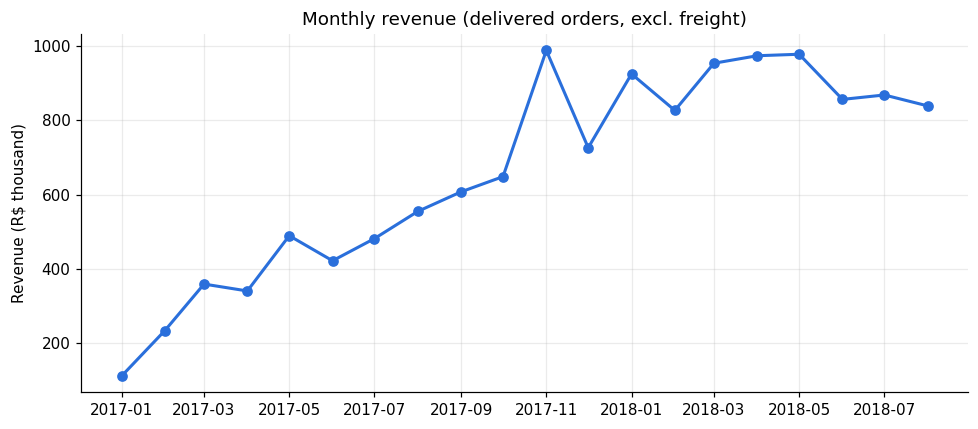

TAKEAWAY: revenue went from R$ 111,798 (Jan 2017) to R$ 838,577 (Aug 2018); peak R$ 987,765 in Nov 2017.


In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(kpi["month"], kpi["revenue"] / 1e3, color=BLUE, marker="o", lw=2)
ax.set_title("Monthly revenue (delivered orders, excl. freight)")
ax.set_ylabel("Revenue (R$ thousand)")
fig.tight_layout(); fig.savefig(IMG / "01_monthly_revenue.png"); plt.show()

a, b = kpi.iloc[0], kpi.iloc[-1]
peak = kpi.loc[kpi["revenue"].idxmax()]
print(f"TAKEAWAY: revenue went from R$ {a.revenue:,.0f} ({a.month:%b %Y}) to R$ {b.revenue:,.0f} ({b.month:%b %Y}); "
      f"peak R$ {peak.revenue:,.0f} in {peak.month:%b %Y}.")

## 2. Top 10 categories by revenue

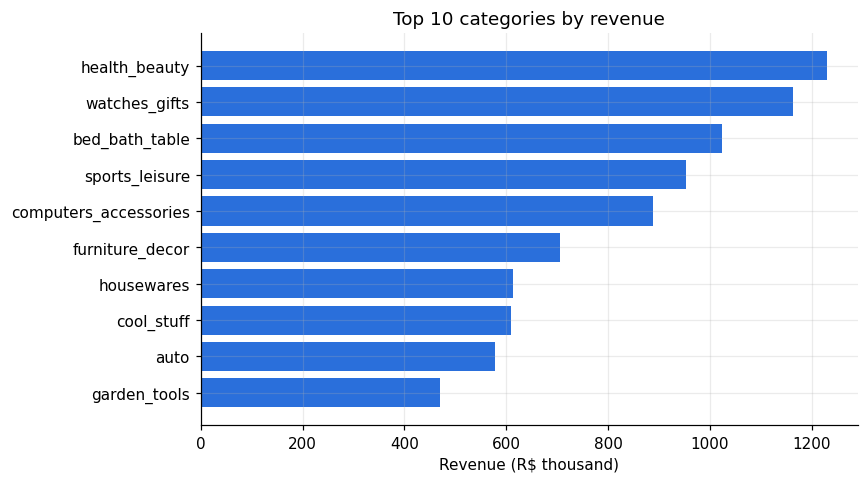

TAKEAWAY: the top 10 categories bring 62% of revenue; #1 is health_beauty (9.3%).


In [3]:
top = cat.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top["category"], top["revenue"] / 1e3, color=BLUE)
ax.set_title("Top 10 categories by revenue"); ax.set_xlabel("Revenue (R$ thousand)")
fig.tight_layout(); fig.savefig(IMG / "02_top_categories.png"); plt.show()

share10 = cat.head(10)["share_pct"].sum()
print(f"TAKEAWAY: the top 10 categories bring {share10:.0f}% of revenue; #1 is {cat.iloc[0].category} "
      f"({cat.iloc[0].share_pct:.1f}%).")

## 3. Delivery time by customer state

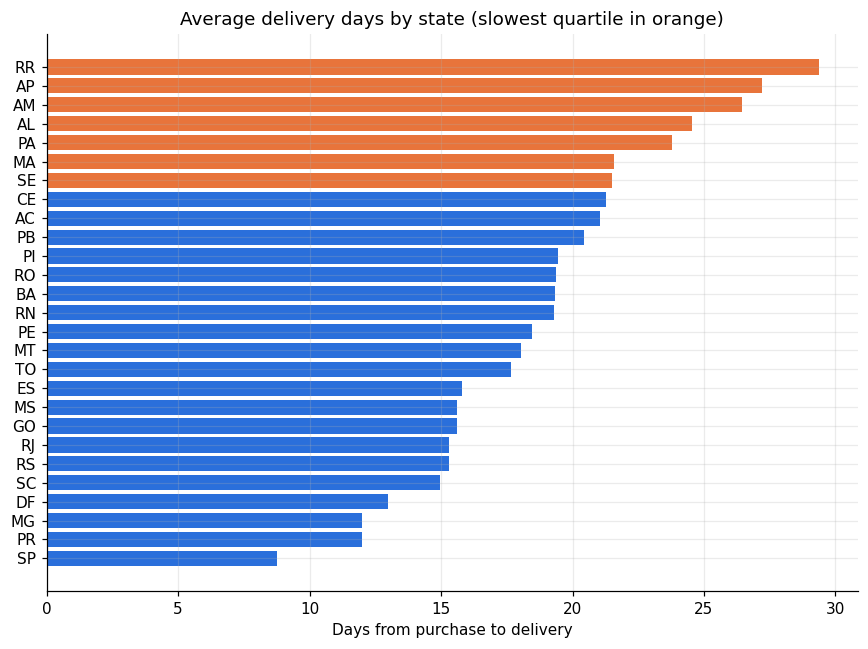

TAKEAWAY: RR waits 29.4 days on average vs SP 8.8 days.


In [4]:
s = st.sort_values("avg_delivery_days")
fig, ax = plt.subplots(figsize=(8, 6))
colors = [ORANGE if v >= s["avg_delivery_days"].quantile(.75) else BLUE for v in s["avg_delivery_days"]]
ax.barh(s["customer_state"], s["avg_delivery_days"], color=colors)
ax.set_title("Average delivery days by state (slowest quartile in orange)"); ax.set_xlabel("Days from purchase to delivery")
fig.tight_layout(); fig.savefig(IMG / "03_delivery_by_state.png"); plt.show()

print(f"TAKEAWAY: {st.iloc[0].customer_state} waits {st.iloc[0].avg_delivery_days:.1f} days on average vs "
      f"{st.iloc[-1].customer_state} {st.iloc[-1].avg_delivery_days:.1f} days.")

## 4. Review scores: on-time vs late

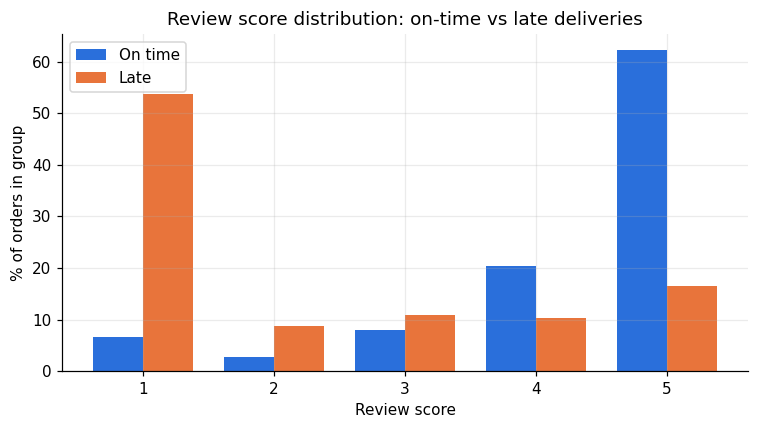

TAKEAWAY: late orders average 2.27 stars vs 4.29 on time (62% of late orders get 1-2 stars).


In [5]:
r = fo[(fo.is_delivered == 1) & fo.is_late.notna() & fo.review_score.notna()].copy()
r["group"] = np.where(r.is_late == 1, "Late", "On time")
r["score"] = r.review_score.round().clip(1, 5).astype(int)
dist = pd.crosstab(r["score"], r["group"], normalize="columns") * 100

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(1, 6); w = .38
ax.bar(x - w/2, dist["On time"], w, label="On time", color=BLUE)
ax.bar(x + w/2, dist["Late"], w, label="Late", color=ORANGE)
ax.set_xlabel("Review score"); ax.set_ylabel("% of orders in group"); ax.legend()
ax.set_title("Review score distribution: on-time vs late deliveries")
fig.tight_layout(); fig.savefig(IMG / "04_review_by_lateness.png"); plt.show()

m = r.groupby("group").review_score.mean()
print(f"TAKEAWAY: late orders average {m['Late']:.2f} stars vs {m['On time']:.2f} on time "
      f"({100*(r[r.group=='Late'].score<=2).mean():.0f}% of late orders get 1-2 stars).")

## 5. Who generates the revenue? Customer segments

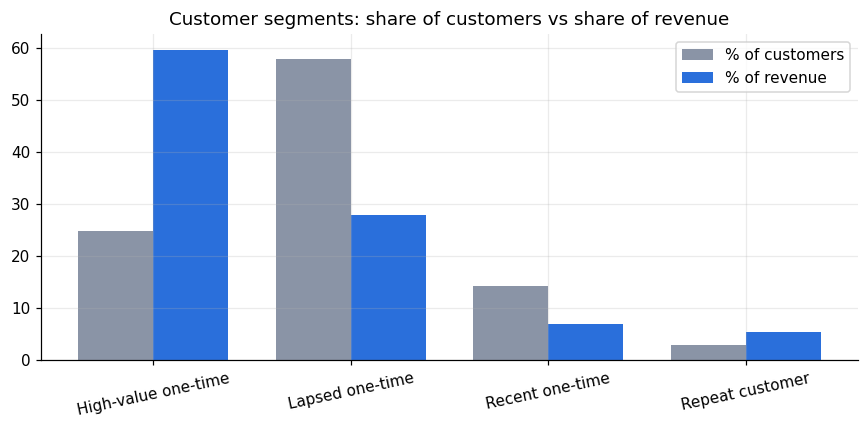

TAKEAWAY: repeat customers are 3.0% of customers and 5.5% of revenue; one-time buyers make up the rest - retention is the growth lever.


In [6]:
order = ["High-value one-time", "Lapsed one-time", "Recent one-time", "Repeat customer"]
sg = seg.set_index("segment").reindex([o for o in order if o in set(seg.segment)])
x = np.arange(len(sg)); w = .38
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - w/2, sg["customer_share_pct"], w, label="% of customers", color=GREY)
ax.bar(x + w/2, sg["revenue_share_pct"], w, label="% of revenue", color=BLUE)
ax.set_xticks(x); ax.set_xticklabels(sg.index, rotation=12); ax.legend()
ax.set_title("Customer segments: share of customers vs share of revenue")
fig.tight_layout(); fig.savefig(IMG / "05_segments.png"); plt.show()

rep = seg[seg.segment == "Repeat customer"].iloc[0]
print(f"TAKEAWAY: repeat customers are {rep.customer_share_pct:.1f}% of customers and {rep.revenue_share_pct:.1f}% of revenue; "
      f"one-time buyers make up the rest - retention is the growth lever.")

## Summary
Paste the five TAKEAWAY lines above into your README under "Key findings", and add the PNGs from `images/`.